# MSE802 Assessment 2 — Task 4: Quantum Machine Learning Analysis
**Author:** Shuohui Liu  
**Date:** 28 October 2026  
**Purpose:** Reproduce the supplied bars-versus-stripes experiment with a Java SDK, record optimization loss and elapsed time, and compare against a circuit-free classical baseline.  
**Status:** Local state-vector quantum simulation is available offline; remote Quokka results require a reachable service.

This notebook preserves the original dataset construction, quantum circuit architecture, and SciPy Nelder–Mead optimization. It replaces direct Python HTTP/QASM logic with a Java SDK. The non-quantum comparator is an independent Hamming-distance classifier, **not** a mathematically equivalent circuit replacement.

## 1. Dependencies and SDK build
Requires JDK 17+, Python, NumPy, SciPy, Matplotlib. Run from the project root; the JAR is built from included Java sources.

In [8]:
# Choose "local" for offline state-vector simulation or "quokka" for remote execution.
# The remote endpoint is only used when QUANTUM_BACKEND == "quokka".
import os
QUANTUM_BACKEND = "quokka" # quokka | local
os.environ["QUOKKA_URL"] = "https://quokka6.quokkacomputing.com/qsim/qasm"
print("Quantum backend:", QUANTUM_BACKEND)
if QUANTUM_BACKEND == "quokka":
    print("Quokka URL:", os.environ["QUOKKA_URL"])


Quantum backend: quokka
Quokka URL: https://quokka6.quokkacomputing.com/qsim/qasm


In [9]:
from pathlib import Path
import subprocess, json, time, csv
import numpy as np
import scipy.optimize as opt
import matplotlib.pyplot as plt

ROOT = Path.cwd()
SDK_DIR = ROOT / 'java-sdk'
JAR = SDK_DIR / 'build' / 'mse802-quantum-sdk.jar'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
if not JAR.exists():
    subprocess.run(['bash', str(SDK_DIR / 'build.sh')], check=True)
print('Java SDK:', JAR)

Java SDK: /Users/michael/Documents/Yoobee/802-Quantom_Computing/assessment_2/quantum_computing_a2_t4/java-sdk/build/mse802-quantum-sdk.jar


## 2. Source-compatible binary image dataset
The original notebook labels stripes as 0 and bars as 1. The 2×2 case contains four images; a 75/25 split therefore gives only one test image. Results are illustrative and statistically limited.

Images: (4, 4) train: [2 1 3] test: [0]


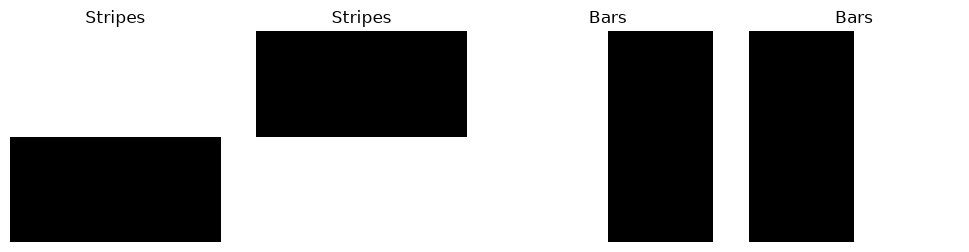

In [10]:
def generate_binary_code(bit_length):
    return np.array([[(number >> bit) & 1 for bit in range(bit_length)]
                     for number in range(2 ** bit_length)], dtype=int)

def generate_data(length):
    patterns = generate_binary_code(length)[1:-1]
    stripes = np.array([np.repeat(p, length) for p in patterns])
    bars = np.array([np.tile(p, length) for p in patterns])
    return np.vstack([stripes, bars])

SIDE = 2
SEED = 802
rng = np.random.default_rng(SEED)
dataset = generate_data(SIDE)
labels = np.r_[np.zeros(2**SIDE - 2), np.ones(2**SIDE - 2)]
indices = rng.permutation(len(dataset))
train_ids, test_ids = indices[:int(.75*len(dataset))], indices[int(.75*len(dataset)):]
training, training_labels = dataset[train_ids], labels[train_ids]
test, test_labels = dataset[test_ids], labels[test_ids]
N_PARAMETERS = 2 * (SIDE*SIDE - 1)
print('Images:', dataset.shape, 'train:', train_ids, 'test:', test_ids)
fig, axes = plt.subplots(1, len(dataset), figsize=(10, 2.5))
for ax, pixels, label in zip(axes, dataset, labels):
    ax.imshow(pixels.reshape(SIDE, SIDE), cmap='gray', vmin=0, vmax=1)
    ax.set_title('Bars' if label else 'Stripes'); ax.axis('off')
plt.tight_layout(); plt.savefig(RESULTS/'dataset.png', dpi=150); plt.show()

## 3. Java SDK interface and quantum backends
The Java JAR generates the original recursive RY/CNOT OpenQASM circuit for **both** backends. The `local` backend runs the QASM using a NumPy state-vector simulator and samples the measured qubit; `quokka` sends the same circuit to the remote Quokka service through Java. The local simulator runs on a classical CPU and is not quantum hardware. The separate classical baseline does not simulate a quantum circuit.

In [11]:
from local_quantum_simulator import sample_probability, probability_one

if QUANTUM_BACKEND not in ("local", "quokka"):
    raise ValueError("QUANTUM_BACKEND must be 'local' or 'quokka'")
quantum_rng = np.random.default_rng(SEED + 1)

def sdk(command, bits, *args):
    completed = subprocess.run(['java', '-jar', str(JAR), command, ''.join(map(str, map(int, bits))),
                                *map(str, args)], capture_output=True, text=True, timeout=120)
    if completed.returncode:
        raise RuntimeError(f'Java SDK failed: {completed.stderr.strip()}')
    return completed.stdout.strip()

def angle_string(angles):
    return ','.join(format(float(x), '.17g') for x in angles)

def quantum_probability(bits, angles, shots=100):
    if QUANTUM_BACKEND == 'local':
        qasm = sdk('circuit', bits, angle_string(angles))
        return sample_probability(qasm, shots, quantum_rng)
    response = json.loads(sdk('quokka', bits, angle_string(angles), shots))
    values = response['result']['c']
    if not values:
        raise ValueError('Quokka returned no measurement samples')
    return float(np.mean(np.asarray(values, dtype=float)))

def classical_probability(bits):
    return float(sdk('classical', bits, SIDE))

initial_angles = np.zeros(N_PARAMETERS)
print('Example circuit:', sdk('circuit', dataset[0], angle_string(initial_angles)))
print('Classical predictions:', [classical_probability(row) for row in dataset])


Example circuit: OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[1];
x q[0];
x q[1];
ry(0.0) q[0];
ry(0.0) q[1];
cx q[0],q[1];
ry(0.0) q[2];
ry(0.0) q[3];
cx q[2],q[3];
ry(0.0) q[1];
ry(0.0) q[3];
cx q[1],q[3];
measure q[3] -> c[0];
Classical predictions: [0.0, 0.0, 1.0, 1.0]


## 4. Quantum objective and optimization
The source computes mean absolute error across training images. We preserve that metric and Nelder–Mead. Both backends use the Java-generated QASM and shot-based measurements. Timing includes Java startup; Quokka also includes network latency. Each recorded row is an **objective evaluation**, not necessarily one optimizer iteration.

In [12]:
SHOTS = 100
MAXITER = 10
quantum_history = []
start_quantum = None

def quantum_objective(params):
    global start_quantum
    if start_quantum is None:
        start_quantum = time.perf_counter()
    t0 = time.perf_counter()
    predictions = [quantum_probability(row, params, SHOTS) for row in training]
    loss = float(np.mean(np.abs(np.asarray(predictions) - training_labels)))
    quantum_history.append({'evaluation': len(quantum_history)+1,
                            'loss': loss, 'duration_s': time.perf_counter()-t0,
                            'elapsed_s': time.perf_counter()-start_quantum,
                            'backend': QUANTUM_BACKEND})
    print(f"Evaluation {len(quantum_history):3d}: loss={loss:.5f}, duration={quantum_history[-1]['duration_s']:.3f}s")
    return loss

RUN_QUANTUM = True
x0 = np.pi * rng.standard_normal(N_PARAMETERS)
quantum_solution = None
if RUN_QUANTUM:
    quantum_solution = opt.minimize(quantum_objective, x0=x0, method='Nelder-Mead',
                                    options={'maxiter': MAXITER})
    print(quantum_solution)
    print('Backend:', QUANTUM_BACKEND)
    if len(test):
        test_predictions = [quantum_probability(row, quantum_solution.x, SHOTS) for row in test]
        quantum_test_accuracy = float(np.mean((np.asarray(test_predictions) >= 0.5) == test_labels))
        print('Quantum held-out accuracy:', quantum_test_accuracy, 'on', len(test), 'sample(s)')
else:
    print('Skipped quantum execution.')


RuntimeError: Java SDK failed: Quokka HTTP 404 at https://quokka6.quokkacomputing.com/qsim/qasm; Location: (not provided); Body: The endpoint quokka6.quokkacomputing.com is offline.

ERR_NGROK_3200

## 5. Circuit-free classical baseline
This deterministic Java algorithm compares each image against valid ideal bar and stripe templates using Hamming distance. It does not invoke any quantum circuit, quantum simulator, or Quokka. Because it has no trainable parameters, its sequence is **per-image inference**, not optimization iterations. We report it separately and avoid misleading iteration-to-iteration claims.

In [ ]:
classical_history = []
classical_start = time.perf_counter()
for i, (row, label) in enumerate(zip(dataset, labels), 1):
    t0 = time.perf_counter()
    prediction = classical_probability(row)
    classical_history.append({'sample': i, 'prediction': prediction, 'label': float(label),
                              'error': abs(prediction-float(label)),
                              'duration_s': time.perf_counter()-t0,
                              'elapsed_s': time.perf_counter()-classical_start})
classical_accuracy = float(np.mean([r['prediction']==r['label'] for r in classical_history]))
print('Classical full-dataset accuracy:', classical_accuracy)
print('Classical total time (including Java startup):', classical_history[-1]['elapsed_s'], 's')

## 6. Required charts: output measure and execution time by evaluation
Quantum charts use **actual collected measurements** from the selected backend. Results and figures are named by backend to avoid presenting local simulation as Quokka execution. The classical comparator chart is shown separately as per-sample inference timing.

In [ ]:
def save_csv(rows, filename):
    if rows:
        with open(RESULTS/filename, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=rows[0].keys())
            writer.writeheader(); writer.writerows(rows)

save_csv(quantum_history, f'quantum_{QUANTUM_BACKEND}_evaluations.csv')
save_csv(classical_history, 'classical_samples.csv')
if quantum_history:
    x = [r['evaluation'] for r in quantum_history]
    fig, ax = plt.subplots(figsize=(8,4))
    ax.plot(x, [r['loss'] for r in quantum_history], marker='o')
    ax.set(xlabel='Objective evaluation number', ylabel='Mean absolute error',
           title=f'Quantum model ({QUANTUM_BACKEND}): output measure per evaluation')
    ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(RESULTS/f'quantum_{QUANTUM_BACKEND}_loss.png', dpi=160); plt.show()
    fig, ax = plt.subplots(figsize=(8,4))
    ax.plot(x, [r['duration_s'] for r in quantum_history], marker='o')
    ax.set(xlabel='Objective evaluation number', ylabel='Wall-clock duration (s)',
           title=f'Quantum model ({QUANTUM_BACKEND}): time per evaluation')
    ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(RESULTS/f'quantum_{QUANTUM_BACKEND}_time.png', dpi=160); plt.show()
else:
    print('No quantum plots yet: quantum execution was not enabled or completed.')
fig, ax = plt.subplots(figsize=(8,4))
ax.plot([r['sample'] for r in classical_history],
        [r['duration_s'] for r in classical_history], marker='o')
ax.set(xlabel='Classical inference sample', ylabel='Wall-clock duration (s)',
       title='Classical baseline: per-sample inference time')
ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(RESULTS/'classical_time.png', dpi=160); plt.show()

## 7. Comparison and interpretation
- **Efficiency:** Quantum training and deterministic classical inference are different workloads; do not claim a speedup from their wall-clock times.
- **Effectiveness:** Report held-out quantum accuracy and classical predictions on the same samples; the 2×2 dataset has only one test sample.
- **Local backend:** State-vector simulation is performed on a classical CPU, with shot outcomes sampled from the exact measurement probability. These are **simulated** quantum-circuit results, not Quokka measurements or hardware execution.
- **Remote backend:** Only describe results as Quokka executions when the live service responds successfully.
- **Limitations:** Tiny dataset, shot noise, different model families, Java startup overhead, and (for Quokka) network latency. A fairer study would use repeated seeds and a trainable classical comparator.
- **Evidence:** Include backend-labeled CSVs and plots, environment details, and remote availability in the report.

### Source mapping
Original `generate_binary_code`/`generate_data` → Python dataset functions. Original `block`/`generate_pairs`/`create_circuit` → Java `circuit`. Original remote `requests.post` → Java `quokka`; local alternative → NumPy state-vector simulation of Java QASM. Original SciPy `minimize` → Python `opt.minimize`. Additional classical comparator → Java `classical`.
